In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import json
import scipy
import tqdm
from copy import deepcopy
import anndata as ad
import SDP_miRNA.dataset
import SDP_miRNA.optimization
import SDP_miRNA.optimization_MOSEK
import SDP_miRNA.correlation

# Load Data

In [2]:
# load counts
data_HEK = pd.read_csv("../../Moment-equations/Real-Data-2/Data/GSE151334_HEK_counts_thresh.csv", index_col=0)

# load capture
beta = np.loadtxt("../../Moment-equations/Real-Data-2/Capture/beta_HEK.txt")

# load RNA types
biotypes_dict = json.load(open("../../Moment-equations/Real-Data-2/Biotypes/biotypes_HEK.json"))

# select indices of protein coding mRNA and non-coding miRNA
pcRNA_indices = [idx for idx, btype in enumerate(biotypes_dict.values()) if btype == "protein_coding"]
miRNA_indices = [idx for idx, btype in enumerate(biotypes_dict.values()) if btype == "miRNA"]

# select protein coding genes
data_HEK_pcRNA = data_HEK.iloc[pcRNA_indices]

# select miRNA
data_HEK_miRNA = data_HEK.iloc[miRNA_indices]

# convert to anndata: transpose to cell x gene convention
adata_miRNA = ad.AnnData(data_HEK_miRNA.T)
adata_pcRNA = ad.AnnData(data_HEK_pcRNA.T)

In [3]:
# max observed count per miRNA
max_count = adata_miRNA.X.max(axis=0)

# select
count_mask = (max_count >= 3).squeeze()
miRNA_idxs = np.arange(len(count_mask))[count_mask]

# subset miRNA
adata_miRNA = adata_miRNA[:, miRNA_idxs]

# display
print(f"{sum(count_mask)} / {len(count_mask)} miRNA retained")

24 / 24 miRNA retained


# SmartSeq - TotalX  Data Comparison

In [4]:
# load pcRNA
adata_pcRNA_TX = ad.read_h5ad("../../TotalX/HEK293T-Cell-Cycle/TotalX_HEK293T_CC_pcRNA.h5ad")

# load miRNA
adata_miRNA_TX = ad.read_h5ad("../../TotalX/HEK293T-Cell-Cycle/TotalX_HEK293T_CC_miRNA.h5ad")

# load capture
beta_TX = np.loadtxt("../../TotalX/HEK293T/TotalX_HEK293T_capture.txt")

## Common microRNAs

In [5]:
# common microRNAs
miRNA_names = adata_miRNA.var.index.tolist()
miRNA_names_TX = adata_miRNA_TX.var['GeneName'].values.tolist()

[x for x in miRNA_names if x in miRNA_names_TX]

['MIR222']

In [6]:
adata_miRNA_TX[:, adata_miRNA_TX.var['GeneName'] == "MIR222"].X.max()

np.float32(2.0)

In [7]:
# additional miRNA selection

# max observed count per miRNA
max_count = adata_miRNA_TX.X.max(axis=0).toarray()

# select
count_mask = (max_count >= 3).squeeze()
miRNA_idxs = np.arange(len(count_mask))[count_mask]

# subset miRNA
adata_miRNA_TX = adata_miRNA_TX[:, miRNA_idxs]

# display
print(f"{sum(count_mask)} / {len(count_mask)} miRNA retained")

20 / 41 miRNA retained


In [8]:
# common microRNAs
miRNA_names = adata_miRNA.var.index.tolist()
miRNA_names_TX = adata_miRNA_TX.var['GeneName'].values.tolist()

[x for x in miRNA_names if x in miRNA_names_TX]

[]

## Cell Counts

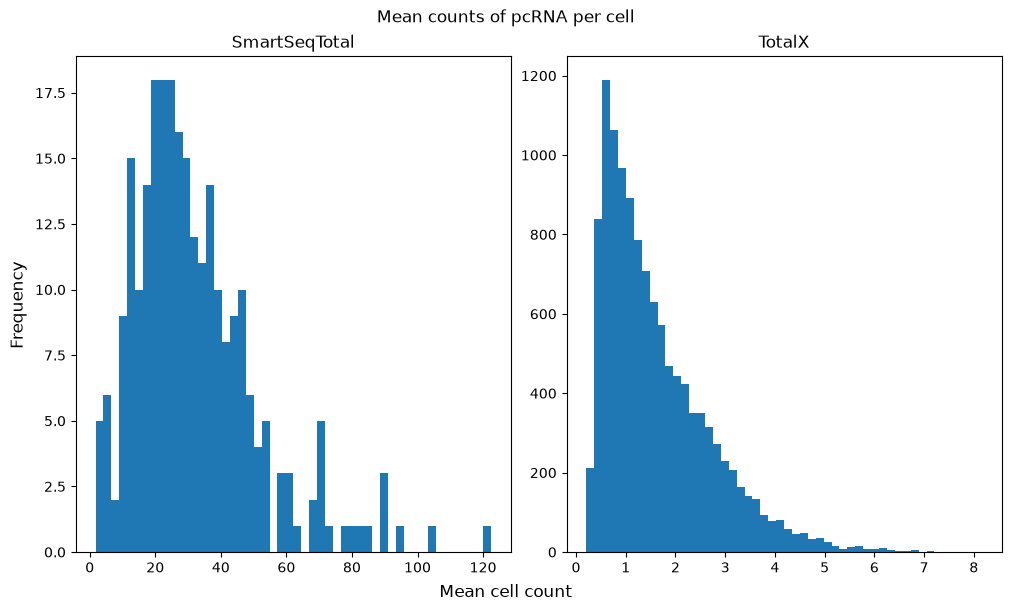

In [9]:
mean_cell_count = adata_pcRNA.X.mean(axis=1)
mean_cell_count_TX = np.array(adata_pcRNA_TX.X.mean(axis=1)).flatten()

fig, axs = plt.subplots(1, 2, figsize=(10, 6), constrained_layout=True)
axs[0].hist(mean_cell_count, bins=50)
axs[0].set_title("SmartSeqTotal")
axs[1].hist(mean_cell_count_TX, bins=50)
axs[1].set_title("TotalX")
fig.supxlabel("Mean cell count")
fig.supylabel("Frequency")
fig.suptitle("Mean counts of pcRNA per cell")
plt.show()

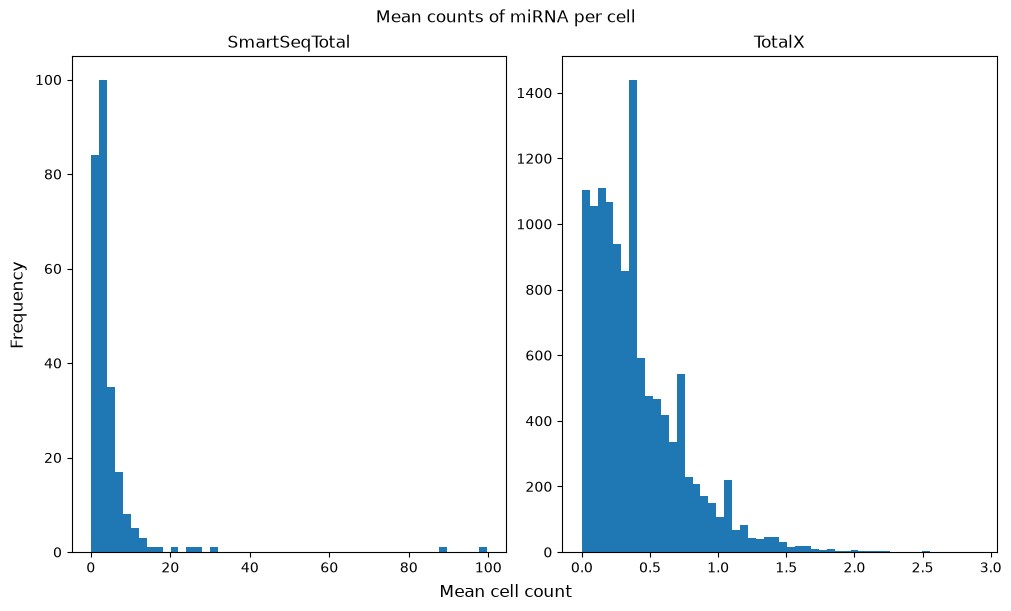

In [10]:
mean_cell_count = adata_miRNA.X.mean(axis=1)
mean_cell_count_TX = np.array(adata_miRNA_TX.X.mean(axis=1)).flatten()

fig, axs = plt.subplots(1, 2, figsize=(10, 6), constrained_layout=True)
axs[0].hist(mean_cell_count, bins=50)
axs[0].set_title("SmartSeqTotal")
axs[1].hist(mean_cell_count_TX, bins=50)
axs[1].set_title("TotalX")
fig.supxlabel("Mean cell count")
fig.supylabel("Frequency")
fig.suptitle("Mean counts of miRNA per cell")
plt.show()

## Gene Expression

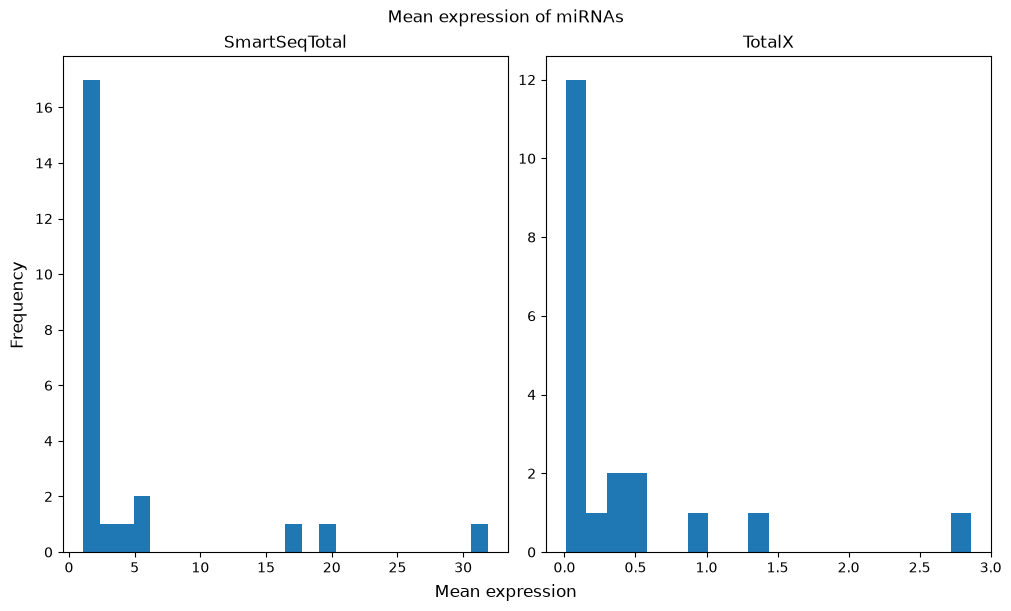

In [11]:
mean_expression = adata_miRNA.X.mean(axis=0)
mean_expression_TX = np.array(adata_miRNA_TX.X.mean(axis=0)).flatten()

fig, axs = plt.subplots(1, 2, figsize=(10, 6), constrained_layout=True)
axs[0].hist(mean_expression, bins=24)
axs[0].set_title("SmartSeqTotal")
axs[1].hist(mean_expression_TX, bins=20)
axs[1].set_title("TotalX")
fig.supxlabel("Mean expression")
fig.supylabel("Frequency")
fig.suptitle("Mean expression of miRNAs")
plt.show()

# SmartSeqTotal Analysis

## Optimization

In [ ]:
# settings
d = 3

# get RNA names
miRNA_names = adata_miRNA.var_names.tolist()
pcRNA_names = adata_pcRNA.var_names.tolist()

# initialize results dataframes
MF_ind_df = pd.DataFrame(index=pcRNA_names)
MF_int_df = pd.DataFrame(index=pcRNA_names)

# loop over miRNA
for i, miRNA in enumerate(miRNA_names):

    # display
    print(f"({i + 1} / {len(miRNA_names)}) {miRNA}")

    # initialize dataset
    SDP_data = SDP_miRNA.dataset.Dataset()

    # construct datasets
    SDP_data.construct_dataset_adata(
        adata_miRNA[:, adata_miRNA.var_names == miRNA],
        adata_pcRNA,
        beta
    )

    # bootstrap
    SDP_data.bootstrap(d=d)

    # model free independence test
    MF_ind = SDP_miRNA.optimization.ModelFreeOptimization(SDP_data, d=d)
    MF_ind.optimized_construction = True
    MF_ind.analyse_dataset()

    # extract results
    status = np.array([sol['status'] for sol in MF_ind.result_dict.values()])

    # store
    MF_ind_df[f'{miRNA}_status'] = status

    # select indices of interacting pairs
    int_idxs = np.arange(status.size)[status == "INFEASIBLE"]

    # reduce gene queries to these
    gene_queries = [query for i, query in enumerate(SDP_data.gene_queries) if i in int_idxs]

    # reduce dataset to interacting pairs
    SDP_data.gene_queries = gene_queries
    SDP_data.total_gene_queries = len(gene_queries)
    SDP_data.moment_bounds = SDP_data.moment_bounds[:, int_idxs, :]

    # model free interacting H&R
    MF_int = SDP_miRNA.optimization_MOSEK.MOSEKModelFreeInteracting(SDP_data, d=d)
    MF_int.analyse_dataset()

    # H&R correlations
    _, HAR_intervals = MF_int.compute_dataset_correlation()
    HAR_mid = (HAR_intervals[:, 0] + HAR_intervals[:, 1]) / 2

    # embedd MF int results (only on interacting pairs) into array of all pairs
    HAR_all = np.empty((adata_pcRNA.n_vars, 3)) * np.nan
    HAR_all[int_idxs, 0] = HAR_intervals[:, 0]
    HAR_all[int_idxs, 1] = HAR_intervals[:, 1]
    HAR_all[int_idxs, 2] = HAR_mid

    # store
    MF_int_df[f'{miRNA}_HAR_min'] = HAR_all[:, 0]
    MF_int_df[f'{miRNA}_HAR_max'] = HAR_all[:, 1]
    MF_int_df[f'{miRNA}_HAR_mid'] = HAR_all[:, 2]

    # write results
    #MF_ind_df.to_csv(f"Results/ind_MF.csv")
    #MF_int_df.to_csv(f"Results/int_MF.csv")

    # display H&R error statistics
    print("H&R error statistics:")
    try:
        print(f"Interval err: {np.unique([dct['err'] for dct in MF_int.HAR_metrics_dict.values()], return_counts=True)}")
    except Exception as e:
        print(e)
    try:
        print(f"Interval eps: {np.unique([dct['eps'] for dct in MF_int.HAR_metrics_dict.values()], return_counts=True)}\n")
    except Exception as e:
        print(e)

(1 / 24) MIR101-1


100%|██████████| 2219/2219 [00:18<00:00, 117.64it/s]


H&R error statistics:
Interval err: (array([0]), array([2219]))
Interval eps: (array([0]), array([2219]))

(2 / 24) MIR103A2


100%|██████████| 2307/2307 [00:20<00:00, 110.77it/s]


H&R error statistics:
Interval err: (array([0]), array([2307]))
Interval eps: (array([0]), array([2307]))

(3 / 24) MIR106B


...

H&R error statistics:
Interval err: (array([0]), array([182]))
Interval eps: (array([0]), array([182]))

(23 / 24) MIR93


100%|██████████| 1245/1245 [00:12<00:00, 99.98it/s] 


H&R error statistics:
Interval err: (array([0]), array([1245]))
Interval eps: (array([0]), array([1245]))

(24 / 24) MIRLET7A1


100%|██████████| 2035/2035 [00:17<00:00, 116.10it/s]


H&R error statistics:
Interval err: (array([0]), array([2035]))
Interval eps: (array([0]), array([2035]))



## Correlation

In [301]:
# settings
d = 3

# get RNA names
miRNA_names = adata_miRNA.var_names.tolist()
pcRNA_names = adata_pcRNA.var_names.tolist()

# initialize results dataframes
corr_df = pd.DataFrame(index=pcRNA_names)

# loop over miRNA
for i, miRNA in enumerate(miRNA_names):

    # display
    print(f"({i + 1} / {len(miRNA_names)}) {miRNA}")

    # initialize dataset
    SDP_data = SDP_miRNA.dataset.Dataset()

    # construct datasets
    SDP_data.construct_dataset_adata(
        adata_miRNA[:, adata_miRNA.var_names == miRNA],
        adata_pcRNA,
        beta
    )

    # OB & AL estimates: point and interval
    OB_corrs, AL_corrs = SDP_miRNA.correlation.compute_correlations(SDP_data)

    # store
    corr_df[f'{miRNA}_OB'] = OB_corrs[:, 0]
    corr_df[f'{miRNA}_OB_min'] = OB_corrs[:, 1]
    corr_df[f'{miRNA}_OB_max'] = OB_corrs[:, 2]
    corr_df[f'{miRNA}_AL'] = AL_corrs[:, 0]
    corr_df[f'{miRNA}_AL_min'] = AL_corrs[:, 1]
    corr_df[f'{miRNA}_AL_max'] = AL_corrs[:, 2]

    # write results
    corr_df.to_csv(f"Results/corr.csv")

(1 / 24) MIR101-1


100%|██████████| 106/106 [00:03<00:00, 29.44it/s]


(2 / 24) MIR103A2


 63%|██████▎   | 67/106 [00:02<00:01, 26.33it/s]c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
100%|██████████| 106/106 [00:03<00:00, 28.14it/s]


(3 / 24) MIR106B


...

 61%|██████▏   | 65/106 [00:01<00:01, 31.70it/s]c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
100%|██████████| 106/106 [00:03<00:00, 34.31it/s]
C:\Users\wjh20\AppData\Local\Temp\ipykernel_36608\3097964741.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  corr_df[f'{miRNA}_OB'] = OB_corrs[:, 0]
C:\Users\wjh20\AppData\Local\Temp\ipykernel_36608\3097964741.py:32: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`


(23 / 24) MIR93


100%|██████████| 106/106 [00:03<00:00, 33.99it/s]
C:\Users\wjh20\AppData\Local\Temp\ipykernel_36608\3097964741.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  corr_df[f'{miRNA}_OB'] = OB_corrs[:, 0]
C:\Users\wjh20\AppData\Local\Temp\ipykernel_36608\3097964741.py:32: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  corr_df[f'{miRNA}_OB_min'] = OB_corrs[:, 1]
C:\Users\wjh20\AppData\Local\Temp\ipykernel_36608\3097964741.py:33: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert

(24 / 24) MIRLET7A1


 60%|██████    | 64/106 [00:01<00:01, 35.17it/s]c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
100%|██████████| 106/106 [00:03<00:00, 33.57it/s]
C:\Users\wjh20\AppData\Local\Temp\ipykernel_36608\3097964741.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  corr_df[f'{miRNA}_OB'] = OB_corrs[:, 0]
C:\Users\wjh20\AppData\Local\Temp\ipykernel_36608\3097964741.py:32: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`


# MIR222 TotalX Comparison

`MIR222` is filtered out of TotalX data for having < 3 max count. But, it is the only common miRNA between the 2 datasets (at least after mean < 1 gene filtering of smartseq data) and its max count is 2, so we can still attempt to analyse and compare.

## TotalX Analysis

MIR222 not analysed so far as has < 3 max count

In [12]:
# load pcRNA
adata_pcRNA_TX = ad.read_h5ad("../../TotalX/HEK293T-Cell-Cycle/TotalX_HEK293T_CC_pcRNA.h5ad")

# load miRNA
adata_miRNA_TX = ad.read_h5ad("../../TotalX/HEK293T-Cell-Cycle/TotalX_HEK293T_CC_miRNA.h5ad")

# load capture
beta_TX = np.loadtxt("../../TotalX/HEK293T/TotalX_HEK293T_capture.txt")

In [13]:
# settings
d = 3
miRNA = "MIR222"

# get RNA names
miRNA_names = adata_miRNA_TX.var['GeneName'].tolist()
pcRNA_names = adata_pcRNA_TX.var['GeneName'].tolist()

# initialize results dataframes
MF_ind_df_TX = pd.DataFrame(index=pcRNA_names)
MF_int_df_TX = pd.DataFrame(index=pcRNA_names)

# initialize dataset
SDP_data = SDP_miRNA.dataset.Dataset()

# construct datasets
SDP_data.construct_dataset_adata(
    adata_miRNA_TX[:, adata_miRNA_TX.var['GeneName'] == miRNA],
    adata_pcRNA_TX,
    beta_TX
)

# bootstrap
SDP_data.bootstrap(d=d)

# model free independence test
MF_ind = SDP_miRNA.optimization.ModelFreeOptimization(SDP_data, d=d)
MF_ind.optimized_construction = True
MF_ind.analyse_dataset()

# extract results
status = np.array([sol['status'] for sol in MF_ind.result_dict.values()])

# store
MF_ind_df_TX[f'{miRNA}_status'] = status

# select indices of interacting pairs
int_idxs = np.arange(status.size)[status == "INFEASIBLE"]

# reduce gene queries to these
gene_queries = [query for i, query in enumerate(SDP_data.gene_queries) if i in int_idxs]

# reduce dataset to interacting pairs
SDP_data.gene_queries = gene_queries
SDP_data.total_gene_queries = len(gene_queries)
SDP_data.moment_bounds = SDP_data.moment_bounds[:, int_idxs, :]

# model free interacting H&R
MF_int = SDP_miRNA.optimization_MOSEK.MOSEKModelFreeInteracting(SDP_data, d=d)
MF_int.analyse_dataset()

# H&R correlations
_, HAR_intervals = MF_int.compute_dataset_correlation()
HAR_mid = (HAR_intervals[:, 0] + HAR_intervals[:, 1]) / 2

# embedd MF int results (only on interacting pairs) into array of all pairs
HAR_all = np.empty((adata_pcRNA_TX.n_vars, 3)) * np.nan
HAR_all[int_idxs, 0] = HAR_intervals[:, 0]
HAR_all[int_idxs, 1] = HAR_intervals[:, 1]
HAR_all[int_idxs, 2] = HAR_mid

# store
MF_int_df_TX[f'{miRNA}_HAR_min'] = HAR_all[:, 0]
MF_int_df_TX[f'{miRNA}_HAR_max'] = HAR_all[:, 1]
MF_int_df_TX[f'{miRNA}_HAR_mid'] = HAR_all[:, 2]

# write results
MF_ind_df_TX.to_csv(f"Results/MIR222_TX_ind_MF.csv")
MF_int_df_TX.to_csv(f"Results/MIR222_TX_int_MF.csv")

# display H&R error statistics
print("H&R error statistics:")
try:
    print(f"Interval err: {np.unique([dct['err'] for dct in MF_int.HAR_metrics_dict.values()], return_counts=True)}")
except Exception as e:
    print(e)
try:
    print(f"Interval eps: {np.unique([dct['eps'] for dct in MF_int.HAR_metrics_dict.values()], return_counts=True)}\n")
except Exception as e:
    print(e)

100%|██████████| 3215/3215 [00:26<00:00, 119.16it/s]

H&R error statistics:
Interval err: (array([0]), array([3215]))
Interval eps: (array([0]), array([3215]))



In [302]:
# settings
miRNA = "MIR222"

# get RNA names
miRNA_names = adata_miRNA_TX.var['GeneName'].tolist()
pcRNA_names = adata_pcRNA_TX.var['GeneName'].tolist()

# initialize results dataframes
corr_df = pd.DataFrame(index=pcRNA_names)

# initialize dataset
SDP_data = SDP_miRNA.dataset.Dataset()

# construct datasets
SDP_data.construct_dataset_adata(
    adata_miRNA_TX[:, adata_miRNA_TX.var['GeneName'] == miRNA],
    adata_pcRNA_TX,
    beta
)

# OB & AL estimates: point and interval
OB_corrs, AL_corrs = SDP_miRNA.correlation.compute_correlations(SDP_data)

# store
corr_df[f'{miRNA}_OB'] = OB_corrs[:, 0]
corr_df[f'{miRNA}_OB_min'] = OB_corrs[:, 1]
corr_df[f'{miRNA}_OB_max'] = OB_corrs[:, 2]
corr_df[f'{miRNA}_AL'] = AL_corrs[:, 0]
corr_df[f'{miRNA}_AL_min'] = AL_corrs[:, 1]
corr_df[f'{miRNA}_AL_max'] = AL_corrs[:, 2]

# write results
corr_df.to_csv(f"Results/MIR222_TX_corr.csv")

100%|██████████| 104/104 [00:44<00:00,  2.31it/s]


## Results

In [12]:
# load results
MF_ind_ST = pd.read_csv("./Results/ind_MF.csv", index_col=0)
MF_int_ST = pd.read_csv("./Results/int_MF.csv", index_col=0)
corr_ST = pd.read_csv("./Results/corr.csv", index_col=0)
MF_ind_TX = pd.read_csv("./Results/MIR222_TX_ind_MF.csv", index_col=0)
MF_int_TX = pd.read_csv("./Results/MIR222_TX_int_MF.csv", index_col=0)
corr_TX = pd.read_csv("./Results/MIR222_TX_corr.csv", index_col=0)

# select just common MIR222
MF_ind_ST = MF_ind_ST[['MIR222_status']]
MF_int_ST = MF_int_ST[['MIR222_HAR_min', 'MIR222_HAR_max', 'MIR222_HAR_mid']]
corr_ST = corr_ST[['MIR222_OB', 'MIR222_OB_min', 'MIR222_OB_max', 'MIR222_AL', 'MIR222_AL_min', 'MIR222_AL_max']]

# select common pcRNA
common_pcRNA = [x for x in MF_ind_ST.index if x in MF_ind_TX.index]
print(f"SmartSeqTotal pcRNA: {len(MF_ind_ST.index)}")
print(f"TotalX pcRNA: {len(MF_ind_TX.index)}")
print(f"Common pcRNA: {len(common_pcRNA)}")
MF_ind_ST = MF_ind_ST.loc[common_pcRNA]
MF_int_ST = MF_int_ST.loc[common_pcRNA]
corr_ST = corr_ST.loc[common_pcRNA]
MF_ind_TX = MF_ind_TX.loc[common_pcRNA]
MF_int_TX = MF_int_TX.loc[common_pcRNA]
corr_TX = corr_TX.loc[common_pcRNA]

SmartSeqTotal pcRNA: 10572
TotalX pcRNA: 10307
Common pcRNA: 9221


### Dependence

In [13]:
MF_ind_df = pd.concat([MF_ind_ST, MF_ind_TX], axis=1)
MF_ind_df.columns = ["ST", "TX"]
comp = MF_ind_df.value_counts()

In [14]:
comp_table = pd.DataFrame(
    [
        [comp['OPTIMAL']['OPTIMAL'], comp['OPTIMAL']['INFEASIBLE']],
        [comp['INFEASIBLE']['OPTIMAL'], comp['INFEASIBLE']['INFEASIBLE']]
    ],
    columns=["Independent", "Dependent"],
    index=["Independent", "Dependent"]
)
comp_table.columns.name = "TotalX"
comp_table.index.name = "SmartSeqTotal"
comp_table.style.background_gradient(cmap="Blues")

TotalX,Independent,Dependent
SmartSeqTotal,,
Independent,6007,2828
Dependent,276,110


### H&R

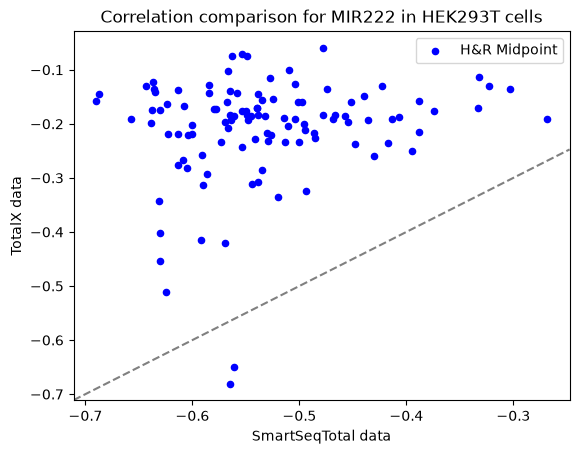

In [15]:
# correlations for common pairs
mask_1 = (MF_ind_ST["MIR222_status"] == "INFEASIBLE").values
mask_2 = (MF_ind_TX["MIR222_status"] == "INFEASIBLE").values
mask = (mask_1 & mask_2)

ST_mid = MF_int_ST['MIR222_HAR_mid'][mask]
TX_mid = MF_int_TX['MIR222_HAR_mid'][mask]

# display
fig, axs = plt.subplots()
axs.scatter(ST_mid, TX_mid, color="blue", label="H&R Midpoint", s=20)
axs.axline([-0.5]*2, [-0.55]*2, color="grey", linestyle="--")
axs.set_xlabel("SmartSeqTotal data")
axs.set_ylabel("TotalX data")
axs.set_title("Correlation comparison for MIR222 in HEK293T cells")
axs.legend()
plt.show()

#### Intervals

Not great plots

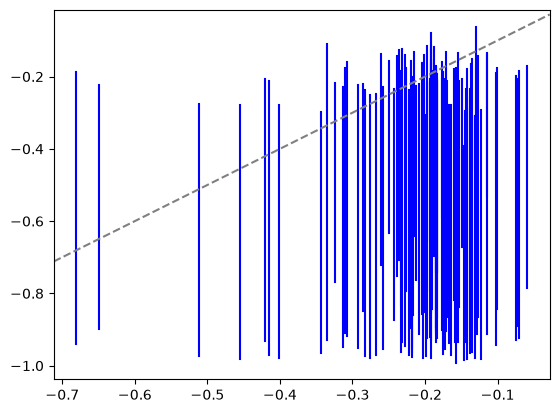

In [16]:
plt.plot(
    np.tile(np.array(MF_int_TX['MIR222_HAR_mid'][mask]), (2, 1)),
    np.array(MF_int_ST[['MIR222_HAR_min', 'MIR222_HAR_max']][mask]).T,
    color="blue"
)
plt.axline([-0.5]*2, [-0.55]*2, color="grey", linestyle="--")

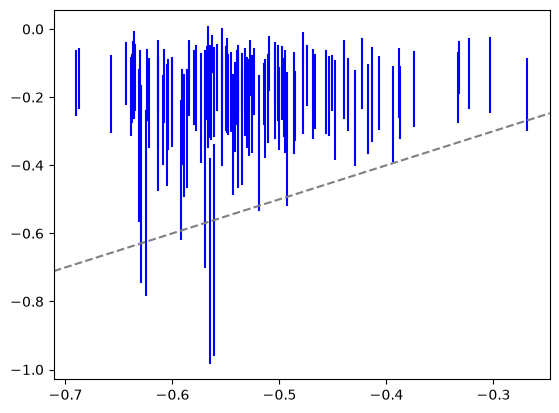

In [17]:
plt.plot(
    np.tile(np.array(MF_int_ST['MIR222_HAR_mid'][mask]), (2, 1)),
    np.array(MF_int_TX[['MIR222_HAR_min', 'MIR222_HAR_max']][mask]).T,
    color="blue"
)
plt.axline([-0.5]*2, [-0.55]*2, color="grey", linestyle="--")

In [18]:
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle

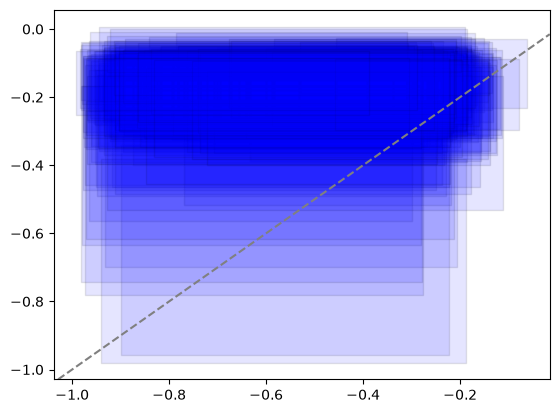

In [19]:
x = MF_int_ST['MIR222_HAR_min'][mask]
xw = MF_int_ST['MIR222_HAR_max'][mask] - MF_int_ST['MIR222_HAR_min'][mask]
y = MF_int_TX['MIR222_HAR_min'][mask]
yw = MF_int_TX['MIR222_HAR_max'][mask] - MF_int_TX['MIR222_HAR_min'][mask]

fig, axs = plt.subplots()

boxes = []
for (xi, xwi, yi, ywi) in zip(x, xw, y, yw):
    boxes.append(Rectangle((xi, yi), xwi, ywi))

pc = PatchCollection(
    boxes,
    facecolor="blue",
    edgecolor="black",
    alpha=0.1
)

axs.add_collection(pc)

axs.axline([-0.5]*2, [-0.55]*2, color="grey", linestyle="--")

plt.show()

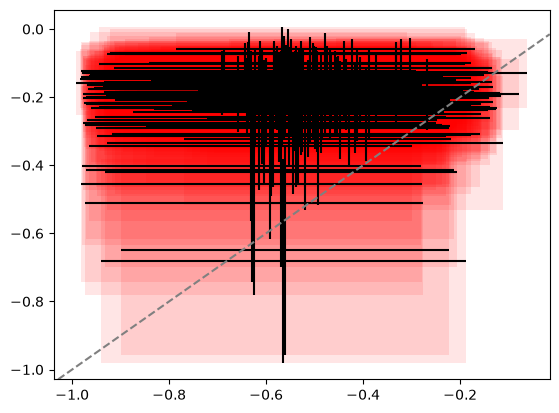

In [20]:
# Dummy data
x = MF_int_ST['MIR222_HAR_mid'][mask]
y = MF_int_TX['MIR222_HAR_mid'][mask]

# Dummy errors (above and below)
xerr = np.array(MF_int_ST[['MIR222_HAR_min', 'MIR222_HAR_max']][mask]).T
yerr = np.array(MF_int_TX[['MIR222_HAR_min', 'MIR222_HAR_max']][mask]).T

xerr[0, :] = np.array(MF_int_ST['MIR222_HAR_mid'][mask]) - xerr[0, :]
xerr[1, :] = xerr[1, :] - np.array(MF_int_ST['MIR222_HAR_mid'][mask])

yerr[0, :] = np.array(MF_int_TX['MIR222_HAR_mid'][mask]) - yerr[0, :]
yerr[1, :] = yerr[1, :] - np.array(MF_int_TX['MIR222_HAR_mid'][mask])

def make_error_boxes(ax, xdata, ydata, xerror, yerror, facecolor='r',
                     edgecolor='none', alpha=0.1):

    # Loop over data points; create box from errors at each point
    errorboxes = [Rectangle((x - xe[0], y - ye[0]), xe.sum(), ye.sum())
                  for x, y, xe, ye in zip(xdata, ydata, xerror.T, yerror.T)]

    # Create patch collection with specified colour/alpha
    pc = PatchCollection(errorboxes, facecolor=facecolor, alpha=alpha,
                         edgecolor=edgecolor)

    # Add collection to Axes
    ax.add_collection(pc)

    # Plot errorbars
    artists = ax.errorbar(xdata, ydata, xerr=xerror, yerr=yerror,
                          fmt='none', ecolor='k')

    return artists


# Create figure and Axes
fig, ax = plt.subplots(1)

# Call function to create error boxes
_ = make_error_boxes(ax, x, y, xerr, yerr)

ax.axline([-0.5]*2, [-0.55]*2, color="grey", linestyle="--")

### OB & AL

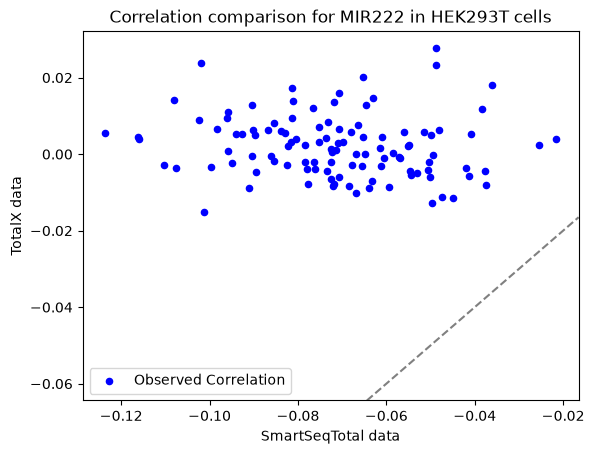

In [21]:
# correlations for common pairs
mask_1 = (MF_ind_ST["MIR222_status"] == "INFEASIBLE").values
mask_2 = (MF_ind_TX["MIR222_status"] == "INFEASIBLE").values
mask = (mask_1 & mask_2)

ST_OB = corr_ST['MIR222_OB'][mask]
TX_OB = corr_TX['MIR222_OB'][mask]

# display
fig, axs = plt.subplots()
axs.scatter(ST_OB, TX_OB, color="blue", label="Observed Correlation", s=20)
axs.axline([-0.05]*2, [-0.06]*2, color="grey", linestyle="--")
axs.set_xlabel("SmartSeqTotal data")
axs.set_ylabel("TotalX data")
axs.set_title("Correlation comparison for MIR222 in HEK293T cells")
axs.legend()
plt.show()

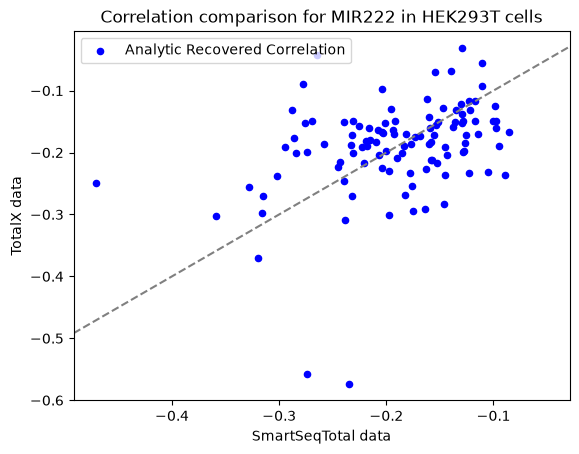

In [22]:
# correlations for common pairs
mask_1 = (MF_ind_ST["MIR222_status"] == "INFEASIBLE").values
mask_2 = (MF_ind_TX["MIR222_status"] == "INFEASIBLE").values
mask = (mask_1 & mask_2)

ST_AL = corr_ST['MIR222_AL'][mask]
TX_AL = corr_TX['MIR222_AL'][mask]

# display
fig, axs = plt.subplots()
axs.scatter(ST_AL, TX_AL, color="blue", label="Analytic Recovered Correlation", s=20)
axs.axline([-0.05]*2, [-0.06]*2, color="grey", linestyle="--")
axs.set_xlabel("SmartSeqTotal data")
axs.set_ylabel("TotalX data")
axs.set_title("Correlation comparison for MIR222 in HEK293T cells")
axs.legend()
plt.show()

#### Intervals

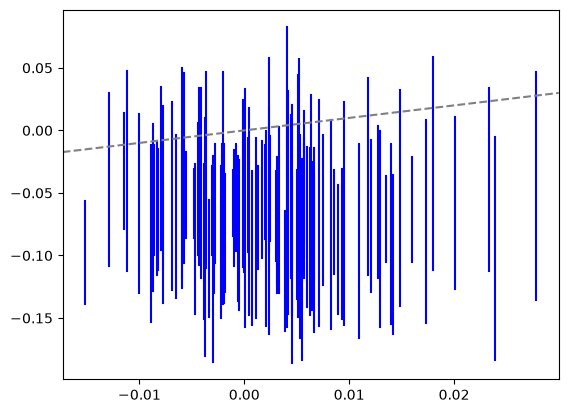

In [23]:
x = np.array(corr_TX['MIR222_OB'][mask])
y = np.array(corr_ST[['MIR222_OB_min', 'MIR222_OB_max']][mask]).T

plt.plot(
    np.tile(x, (2, 1)), y, color="blue")

m = np.mean(x)
eps = 0.01
plt.axline([m]*2, [m + eps]*2, color="grey", linestyle="--")

## Observed - Recovered Histogram

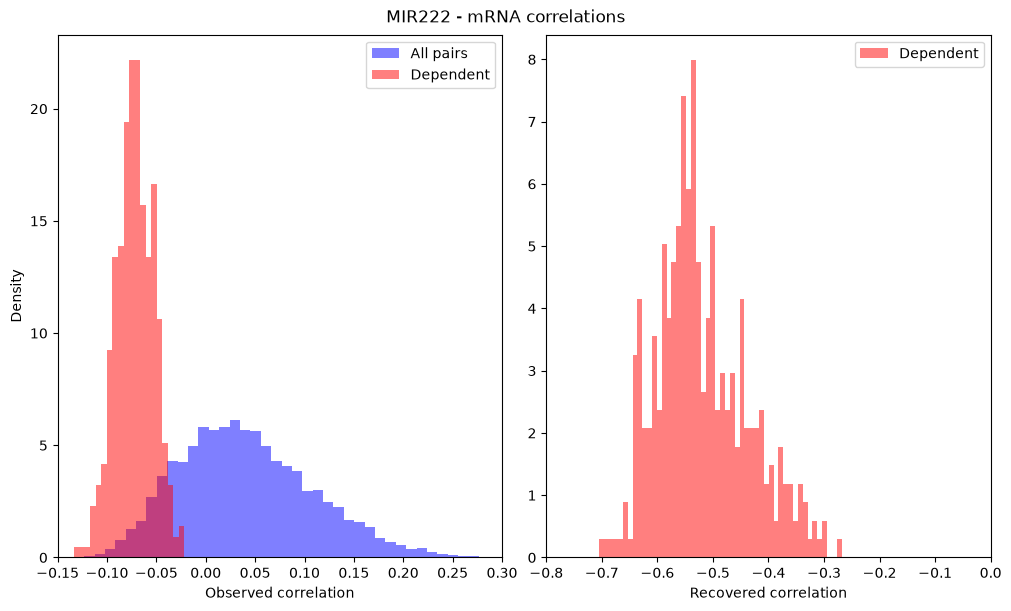

In [24]:
# settings
miRNA = "MIR222"
MF_ind_data = MF_ind_ST
MF_int_data = MF_int_ST
corr_data = corr_ST

fig, axs = plt.subplots(1, 2, figsize=(10, 6), constrained_layout=True)

mask = (MF_ind_data[f'{miRNA}_status'] == "INFEASIBLE").values.squeeze()
mid = MF_int_data[f'{miRNA}_HAR_mid']
OB = corr_data[f'{miRNA}_OB']

axs[0].hist(OB, bins=50, color="blue", alpha=0.5, density=True, label="All pairs")
axs[0].hist(OB[mask], bins=20, color="red", alpha=0.5, density=True, label="Dependent")

axs[1].hist(mid[mask], bins=50, color="red", alpha=0.5, density=True, label="Dependent")

axs[0].set_xlabel("Observed correlation")
axs[0].set_ylabel("Density")
axs[1].set_xlabel("Recovered correlation")

axs[0].legend()
axs[1].legend()

fig.suptitle(f"{miRNA} - mRNA correlations")

axs[0].set_xlim(-0.15, 0.3)
axs[1].set_xlim(-0.8, 0.0)

plt.show()

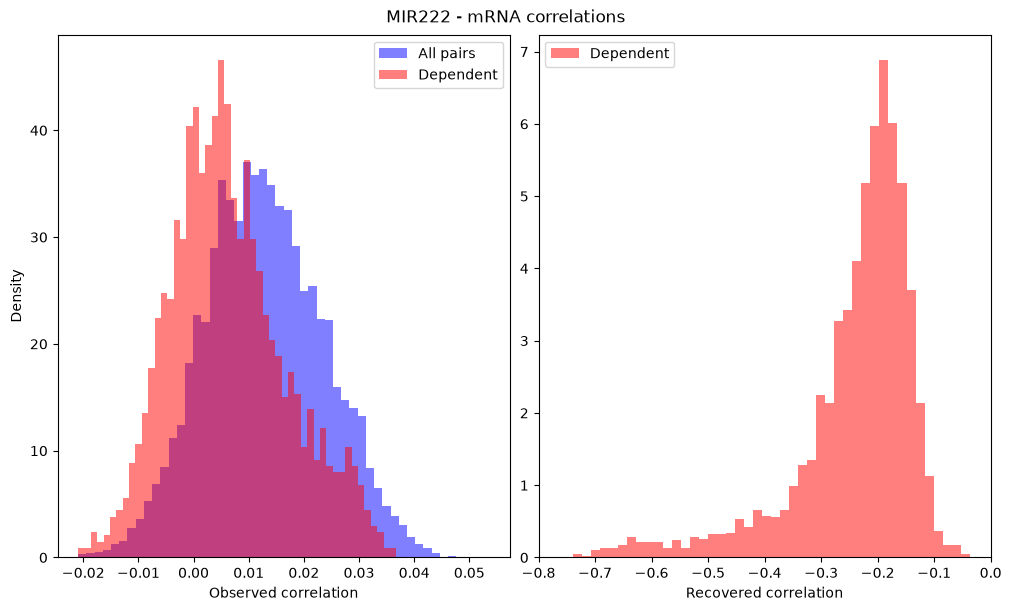

In [25]:
# settings
miRNA = "MIR222"
MF_ind_data = MF_ind_TX
MF_int_data = MF_int_TX
corr_data = corr_TX

fig, axs = plt.subplots(1, 2, figsize=(10, 6), constrained_layout=True)

mask = (MF_ind_data[f'{miRNA}_status'] == "INFEASIBLE").values.squeeze()
mid = MF_int_data[f'{miRNA}_HAR_mid']
OB = corr_data[f'{miRNA}_OB']

axs[0].hist(OB, bins=50, color="blue", alpha=0.5, density=True, label="All pairs")
axs[0].hist(OB[mask], bins=50, color="red", alpha=0.5, density=True, label="Dependent")

axs[1].hist(mid[mask], bins=50, color="red", alpha=0.5, density=True, label="Dependent")

axs[0].set_xlabel("Observed correlation")
axs[0].set_ylabel("Density")
axs[1].set_xlabel("Recovered correlation")

axs[0].legend()
axs[1].legend()

fig.suptitle(f"{miRNA} - mRNA correlations")

#axs[0].set_xlim(-0.15, 0.3)
axs[1].set_xlim(-0.8, 0.0)

plt.show()

# TotalX Comparison

Only the microRNA MIR222 is common to SmartSeqTotal and TotalX data, but it has low expression in TotalX observations, and we see the results are not so similar above.

Now compare all microRNA between SmartSeqTotal and TotalX to see if there is any similarity given different sets of microRNA but the same cell type, HEK293T

In [26]:
# load ST results
MF_ind_ST = pd.read_csv("./Results/ind_MF.csv", index_col=0)
MF_int_ST = pd.read_csv("./Results/int_MF.csv", index_col=0)
corr_ST = pd.read_csv("./Results/corr.csv", index_col=0)

# load TX results
MF_ind_TX = pd.read_csv("../../TotalX/HEK293T-Cell-Cycle/Results/ind_MF.csv", index_col=0)
MF_int_TX = pd.read_csv("../../TotalX/HEK293T-Cell-Cycle/Results/int_MF.csv", index_col=0)
corr_TX = pd.read_csv("../../TotalX/HEK293T-Cell-Cycle/Results/corr.csv", index_col=0)

# select results for all cells
MF_ind_TX = MF_ind_TX[[x for x in MF_ind_TX.columns if "All" in x]]
MF_int_TX = MF_int_TX[[x for x in MF_int_TX.columns if "All" in x]]
corr_TX = corr_TX[[x for x in corr_TX.columns if "All" in x]]

# rename columns
MF_ind_TX.columns = [x.replace("All_", "") for x in MF_ind_TX.columns]
MF_int_TX.columns = [x.replace("All_", "") for x in MF_int_TX.columns]
corr_TX.columns = [x.replace("All_", "") for x in corr_TX.columns]

# select common pcRNA
common_pcRNA = [x for x in MF_ind_ST.index if x in MF_ind_TX.index]
print(f"SmartSeqTotal pcRNA: {len(MF_ind_ST.index)}")
print(f"TotalX pcRNA: {len(MF_ind_TX.index)}")
print(f"Common pcRNA: {len(common_pcRNA)}")
MF_ind_ST = MF_ind_ST.loc[common_pcRNA]
MF_int_ST = MF_int_ST.loc[common_pcRNA]
corr_ST = corr_ST.loc[common_pcRNA]
MF_ind_TX = MF_ind_TX.loc[common_pcRNA]
MF_int_TX = MF_int_TX.loc[common_pcRNA]
corr_TX = corr_TX.loc[common_pcRNA]

SmartSeqTotal pcRNA: 10572
TotalX pcRNA: 10307
Common pcRNA: 9221


## Observed - Recovered Histogram

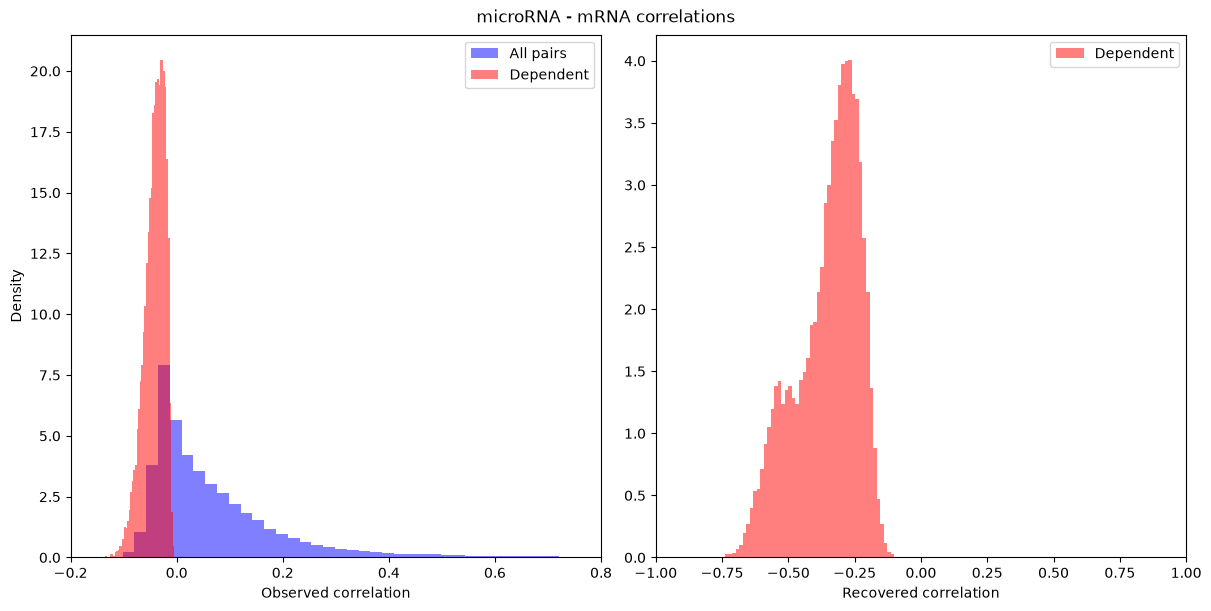

In [32]:
# settings
MF_ind_data = MF_ind_ST
MF_int_data = MF_int_ST
corr_data = corr_ST
miRNA_names = [x.split('_')[0] for x in MF_ind_data.columns]

fig, axs = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)

OB_all = []
OB_mask_all = []
mid_mask_all = []
for miRNA in miRNA_names:
    mask = (MF_ind_data[f'{miRNA}_status'] == "INFEASIBLE").values.squeeze()
    mid = MF_int_data[f'{miRNA}_HAR_mid']
    OB = corr_data[f'{miRNA}_OB']

    OB_all += OB.tolist()
    OB_mask_all += OB[mask].tolist()
    mid_mask_all += mid[mask].tolist()

axs[0].hist(OB_all, bins=50, color="blue", alpha=0.5, density=True, label="All pairs")
axs[0].hist(OB_mask_all, bins=50, color="red", alpha=0.5, density=True, label="Dependent")

axs[1].hist(mid_mask_all, bins=50, color="red", alpha=0.5, density=True, label="Dependent")

axs[0].legend()
axs[1].legend()

axs[0].set_xlabel("Observed correlation")
axs[0].set_ylabel("Density")
axs[1].set_xlabel("Recovered correlation")

axs[0].set_xlim(-0.2, 0.8)
axs[1].set_xlim(-1.0, 1.0)

fig.suptitle("microRNA - mRNA correlations")

plt.show()

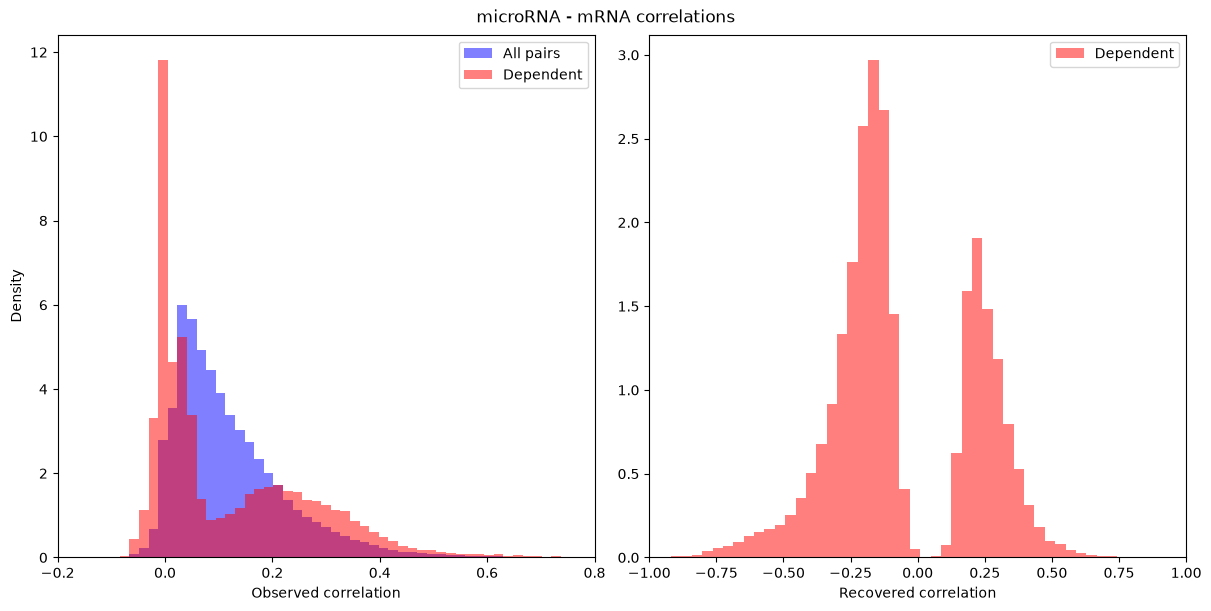

In [30]:
# settings
MF_ind_data = MF_ind_TX
MF_int_data = MF_int_TX
corr_data = corr_TX
miRNA_names = [x.split('_')[0] for x in MF_ind_data.columns]

fig, axs = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)

OB_all = []
OB_mask_all = []
mid_mask_all = []
for miRNA in miRNA_names:
    mask = (MF_ind_data[f'{miRNA}_status'] == "INFEASIBLE").values.squeeze()
    mid = MF_int_data[f'{miRNA}_HAR_mid']
    OB = corr_data[f'{miRNA}_OB']

    OB_all += OB.tolist()
    OB_mask_all += OB[mask].tolist()
    mid_mask_all += mid[mask].tolist()

axs[0].hist(OB_all, bins=50, color="blue", alpha=0.5, density=True, label="All pairs")
axs[0].hist(OB_mask_all, bins=50, color="red", alpha=0.5, density=True, label="Dependent")

axs[1].hist(mid_mask_all, bins=50, color="red", alpha=0.5, density=True, label="Dependent")

axs[0].legend()
axs[1].legend()

axs[0].set_xlabel("Observed correlation")
axs[0].set_ylabel("Density")
axs[1].set_xlabel("Recovered correlation")

axs[0].set_xlim(-0.2, 0.8)
axs[1].set_xlim(-1.0, 1.0)

fig.suptitle("microRNA - mRNA correlations")

plt.show()

# Appendix

## H&R "eps" comment

For hit and run sampling we choose a random direction and find the 2 points on this line that are on the boundary of the feasible set:
- "err" is recorded if a numerical error means there are no points (error as initial point known to be feasible)
- "eps" is recored if the points are within a distance of epsilon (10**-6 default), and no update is made as the change is too small

The SmartSeqTotal analysis above had no "err", but several pairs had 999 interval "eps" warnings out of 999 sampling steps.

Looking at the moment bounds for such a pair we see immediately that the cross moments do not have an interval, but are exatly 0. And this is because no cell has non-zero counts for both the miRNA and pcRNA, as shown below.

This causes the H&R sampling to be unable to explore the space, as we have an equality constraint for at least one dimension which will lead to infeasibility unless the randomly sampled direction is exactly zero in these dimensions.

To fix we extend the idea already used for the 0th order moment, which is equal to 1, and for each dimension with 0 bound width set the direction vector to 0:

In [27]:
# settings
d = 3
miRNA = "MIRLET7A1"
pcRNA_idx = 366

# initialize dataset
SDP_data = SDP_miRNA.dataset.Dataset()

# construct datasets
SDP_data.construct_dataset_adata(
    adata_miRNA[:, adata_miRNA.var_names == miRNA],
    adata_pcRNA[:, pcRNA_idx],
    beta
)

# bootstrap
SDP_data.bootstrap(d=d)

# model free interacting H&R
MF_int = SDP_miRNA.optimization_MOSEK.MOSEKModelFreeInteracting(SDP_data, d=d)
MF_int.use_optimized_hit_and_run = False
MF_int.analyse_dataset()

100%|██████████| 1/1 [00:00<00:00,  2.11it/s]


In [28]:
# HAR metrics
MF_int.HAR_metrics_dict[0]

{'err': 0, 'eps': 0}

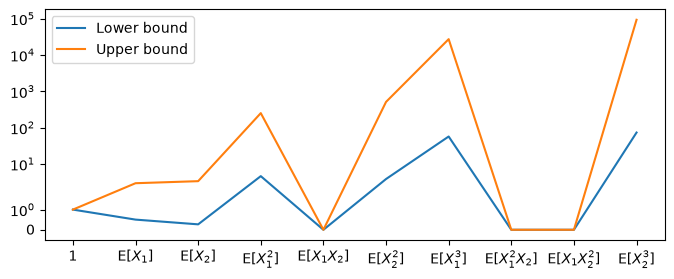

In [29]:
fig, axs = plt.subplots(figsize=(8, 3))
lb = SDP_data.moment_bounds[0, 0, :]
ub = SDP_data.moment_bounds[1, 0, :]
axs.plot(lb, label="Lower bound")
axs.plot(ub, label="Upper bound")
axs.set_yscale('symlog')
axs.set_xticks(range(len(lb)))
axs.set_xticklabels([
    "1",
    r"E[$X_{1}$]", r"E[$X_{2}$]",
    r"E[$X_{1}^{2}$]", r"E[$X_{1} X_{2}$]", r"E[$X_{2}^{2}$]",
    r"E[$X_{1}^{3}$]", r"E[$X_{1}^{2} X_{2}$]", r"E[$X_{1} X_{2}^{2}$]", r"E[$X_{2}^{3}$]"
])
axs.legend()
plt.show()

In [23]:
# get counts of pair
counts_miRNA = adata_miRNA[:, adata_miRNA.var_names == miRNA].X.toarray().squeeze()
counts_pcRNA = adata_pcRNA[:, pcRNA_idx].X.toarray().squeeze()

# non-zero counts
mask_1 = (counts_pcRNA > 0)
mask_2 = (counts_miRNA > 0)

# any cell with non-zero counts for both?
np.any(mask_1 & mask_2)

np.False_

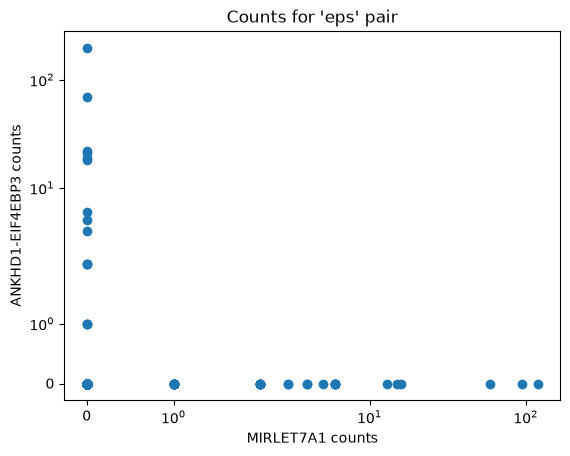

In [24]:
plt.scatter(counts_miRNA, counts_pcRNA)
plt.xlabel(f"{miRNA} counts")
plt.ylabel(f"{adata_pcRNA.var_names[pcRNA_idx]} counts")
plt.title("Counts for 'eps' pair")
plt.xscale('symlog')
plt.yscale('symlog')
plt.show()

## H&R infeasible comment

Independence test assumes that infeasibility is caused by the factorization constraints and that removing these to give the model free interacting optimization should always be feasible (as this simply constrains OG moments to a valid vector).

However, a small number of pairs (6) in the TotalX analysis above remain infeasible, suggesting the infeasibility is caused by the bounds alone due to: small bounds + bootstrap variability + numerical errors, etc?

Unclear quite why this happens, even investigating an example

Fix package to avoid running H&R for these pairs, and to record optimization feasibility in `feasibility_dict`

In [145]:
errs = [dct['eps'] for dct in MF_int.HAR_metrics_dict.values()]
len([x for x in errs if x is None]), np.unique([x for x in errs if x is not None], return_counts=True)

(6, (array([0]), array([3077])))

In [144]:
errs = [dct['err'] for dct in MF_int.HAR_metrics_dict.values()]
len([x for x in errs if x is None]), np.unique([x for x in errs if x is not None], return_counts=True)

(6, (array([0]), array([3077])))

In [160]:
[i for i, x in enumerate(errs) if x is None]

[150, 883, 2389, 2672, 2722, 2869]

In [149]:
MF_int.HAR_metrics_dict[150]

{'err': None, 'eps': None}

In [162]:
# convert index for H&R pairs (only interacting) to full index
idx = int_idxs[150]
idx

np.int64(549)

### Example

Model free interacting optimization, just moment bounds + matrices constrained:
- consistently infeasible for d = 3, feasible for d = 2
- bound widths are non-zero, and results consistent when weakening bootstrap intervals (lower confidence, fewer samples, etc)
- scatter shows miRNA counts take few unqiue values, but generally normal counts
- IIS shows infeasible given just a few bounds and cutting planes, but unclear exactly why

Overall unclear exactly why infeasible, potentially some kind of degeneracy in third order moments?

In [13]:
from SDP_miRNA.constraints import Constraint

In [14]:
# settings
d = 3
miRNA = "MIR222"
pcRNA_idx = 549

# initialize dataset
SDP_data_test = SDP_miRNA.dataset.Dataset()

# construct datasets
SDP_data_test.construct_dataset_adata(
    adata_miRNA_TX[:, adata_miRNA_TX.var['GeneName'] == miRNA],
    adata_pcRNA_TX[:, pcRNA_idx],
    beta_TX
)

# bootstrap
SDP_data_test.bootstrap(d=d)

# model free optimization: no factorization constraint
MF_ind_test = SDP_miRNA.optimization.ModelFreeOptimization(SDP_data_test, d=d)
MF_ind_test.constraints = Constraint(
    moment_bounds=True,
    moment_matrices=True,
    factorization=False
)
MF_ind_test.optimized_construction = True
MF_ind_test.save_model = "test.lp"

# optimize
MF_ind_test.analyse_dataset()

# results
MF_ind_test.result_dict

100%|██████████| 1/1 [00:00<00:00, 31.46it/s]


{0: {'status': 'INFEASIBLE', 'time': 0.01100015640258789, 'cuts': 2}}

In [15]:
# model free interacting H&R
MF_int_test = SDP_miRNA.optimization_MOSEK.MOSEKModelFreeInteracting(SDP_data_test, d=d)
MF_int_test.use_optimized_hit_and_run = False
MF_int_test.analyse_dataset()

100%|██████████| 1/1 [00:00<00:00, 10.83it/s]


In [16]:
MF_int_test.feasibility_dict

{0: 'INFEASIBLE'}

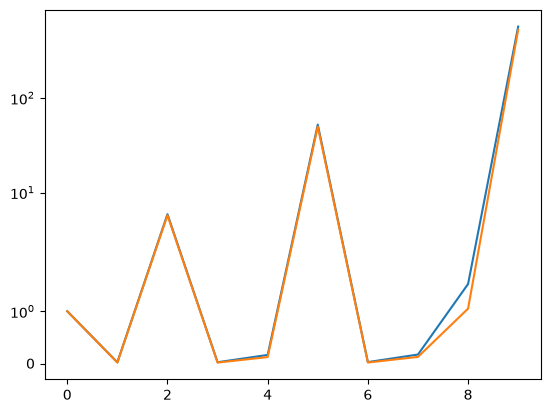

In [240]:
lb = MF_ind_test.dataset.moment_bounds[0, 0, :]
ub = MF_ind_test.dataset.moment_bounds[1, 0, :]
plt.plot(ub)
plt.plot(lb)
plt.yscale('symlog')

In [ ]:
import gurobipy as gp
env = gp.Env()
model = gp.read("test.lp", env)
model.optimize()

Set parameter Username
Set parameter LicenseID to value 2848486
Academic license - for non-commercial use only - expires 2027-07-27
Read LP format model from file test.lp
Reading time = 0.01 seconds
: 26 rows, 10 columns, 67 nonzeros
Gurobi Optimizer version 13.0.2 build v13.0.2rc1 (win64 - Windows 11.0 (22631.2))

CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]
Thread count: 12 physical cores, 14 logical processors, using up to 14 threads

Optimize a model with 26 rows, 10 columns and 67 nonzeros (Min)
Model fingerprint: 0xf2f38642
Model has 0 linear objective coefficients
Coefficient statistics:
  Matrix range     [6e-05, 1e+00]
  Objective range  [0e+00, 0e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [2e-02, 6e+02]

Presolve removed 9 rows and 1 columns
Presolve time: 0.01s

Solved in 0 iterations and 0.01 seconds (0.00 work units)
Infeasible model


In [190]:
model.computeIIS()
model.write("test.ilp")

Gurobi Optimizer version 13.0.2 build v13.0.2rc1 (win64 - Windows 11.0 (22631.2))

CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]
Thread count: 12 physical cores, 14 logical processors, using up to 14 threads


IIS computed: 11 constraints and 0 bounds
IIS runtime: 0.00 seconds (0.00 work units)


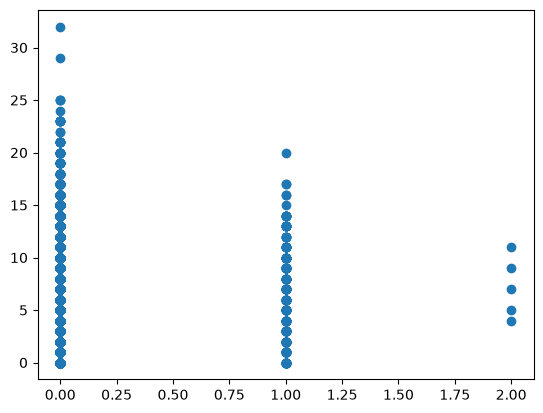

In [182]:
counts_miRNA = adata_miRNA_TX[:, adata_miRNA_TX.var['GeneName'] == miRNA].X.toarray().flatten()
counts_pcRNA = adata_pcRNA_TX[:, pcRNA_idx].X.toarray().flatten()

plt.scatter(counts_miRNA, counts_pcRNA)